# 1 · Data: SWISSIMAGE 2023, swissTLM3D and Rapid Mapping

**Project:** building change in Blatten (Lötschental) after the ice-rock avalanche of 28 May 2025.

This notebook prepares everything the change detector needs, following the course's data pipeline
(L02 data acquisition → L04 masks and chips → L06 quality control and splits → L10 page 2 comparability checks):

1. Search the swisstopo STAC catalogue and read **SWISSIMAGE 2023** for six areas in the Lötschental.
2. Stream only the building layer of **swissTLM3D** and subset it to the valley (labels).
3. Read the **Rapid Mapping** orthophotos of 19 May 2025 (pre-event) and 30 May 2025 (post-event) for Blatten.
4. Rasterize the footprints to masks on the image grid, check them visually, and cut image/mask chips
   with a **spatial** train / validation / test split.
5. Check that the two Rapid Mapping dates are comparable (dates, coverage, co-registration).

The training notebook (`02_train_change_detector.ipynb`) and the application notebook
(`03_blatten_change_map.ipynb`) only read files written here.

## A. Imports and settings

All settings are in the next cell.

In [1]:
import shutil
import tempfile
import time
import warnings
import zipfile
from pathlib import Path

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.merge import merge
from rasterio.transform import from_origin
from rasterio.windows import Window
from skimage.registration import phase_cross_correlation

warnings.filterwarnings("ignore", category=UserWarning)

# ============================ DATA SETTINGS ==================================
STAC_URL = "https://data.geo.admin.ch/api/stac/v1"
CRS = "EPSG:2056"  # Swiss LV95, metres
RES = 0.5  # analysis resolution in metres (SWISSIMAGE is 0.1 m, see step B)

SWISSIMAGE_YEAR = "2023"
TLM_LABEL_RELEASE = "2025-03"  # last release before the event; Lötschental revised from the 2023 flight
TLM_POST_RELEASE = "2026-02"  # first release after the event, used only as an evaluation reference
RAPID_PRE = "ram-2025-05-19t12570000"  # Rapid Mapping flight 19 May 2025 (pre-event)
RAPID_POST = "ram-2025-05-30t08090000"  # Rapid Mapping flight 30 May 2025 (post-event)

# Areas in LV95 (xmin, ymin, xmax, ymax). Whole villages go to one split only (L06: "new place").
REGIONS = {
    "ferden": {"split": "train", "bounds": (2624250, 1137550, 2625000, 1138450)},
    "kippel": {"split": "train", "bounds": (2625000, 1138150, 2625850, 1139050)},
    "lauchernalp": {"split": "train", "bounds": (2625150, 1139700, 2626350, 1140800)},
    "wiler": {"split": "val", "bounds": (2625950, 1138800, 2627250, 1139650)},
    "fafleralp": {"split": "test", "bounds": (2630900, 1141800, 2633300, 1143100)},
    "blatten": {"split": "event", "bounds": (2627800, 1140000, 2630200, 1141950)},
}

# swissTLM3D object types that appear as roofs in an orthophoto
BUILDING_TYPES = ["Gebaeude", "Offenes Gebaeude", "Kapelle", "Sakrales Gebaeude", "Im Bau", "Sakraler Turm"]

CHIP_SIZE = 256  # pixels = 128 m at 0.5 m
TRAIN_STRIDE = 128  # overlapping chips inside the training villages
EVAL_STRIDE = 256  # no overlap for validation and test
KEEP_EMPTY_FRACTION = 0.2  # share of chips without any building that is kept as negatives
SEED = 0
# ==============================================================================

# Notebooks live in notebooks/; data/ and outputs/ sit one level up (project root).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
CHIPS = ROOT / "data/chips"
FIGURES = ROOT / "outputs/figures"
for folder in [RAW, PROCESSED, CHIPS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

to_wgs84 = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True)
catalog = pystac_client.Client.open(STAC_URL)
print("Regions:", {name: r["split"] for name, r in REGIONS.items()})

Regions: {'ferden': 'train', 'kippel': 'train', 'lauchernalp': 'train', 'wiler': 'val', 'fafleralp': 'test', 'blatten': 'event'}


| Setting | Value | Why |
|---|---|---|
| `RES` | 0.5 m | A chalet of 10 × 12 m covers about 20 × 24 pixels, a 256-pixel chip shows 128 m of context, and training stays feasible on a laptop CPU. The L04 SWISSIMAGE example uses the same 0.5 m. |
| `TLM_LABEL_RELEASE` | 2025-03 | The labels must describe the same moment as the image (L06, "same CRS is not enough"). In this release **every** building in the valley has revision year 2023, i.e. it was updated from the 2023 SWISSIMAGE flight (checked in step C). A release published before the flight (e.g. 2023-03, released in March 2023) cannot contain that revision. |
| `REGIONS` | villages | Ferden, Kippel and Lauchernalp train the model, Wiler validates it, Fafleralp tests it. Blatten (with Weissenried and Ried) is never used for training: it is reserved for the real event. |

## B. SWISSIMAGE 2023 via the STAC API

SWISSIMAGE is published as 1 × 1 km Cloud-Optimized GeoTIFF tiles at 0.1 m. As in L02, we search the
STAC catalogue for the tiles that intersect each area and read only the window we need. Because the
files contain internal overviews, a decimated read at 0.5 m transfers only a small part of each tile.
`rasterio.merge.merge()` mosaics the tiles directly onto the 0.5 m analysis grid, with **average**
resampling (each 0.5 m pixel is the mean of the 0.1 m pixels it covers).

In [2]:
def region_grid(bounds, res=RES):
    """Return transform, width and height of the analysis grid for a region."""
    xmin, ymin, xmax, ymax = bounds
    width, height = round((xmax - xmin) / res), round((ymax - ymin) / res)
    return from_origin(xmin, ymax, res, res), width, height


def search_assets(collection, bounds, datetime=None, ids=None, suffix=".tif"):
    """Find the hrefs of all STAC assets whose key ends with `suffix` and that intersect `bounds`."""
    xmin, ymin, xmax, ymax = bounds
    lon0, lat0 = to_wgs84.transform(xmin, ymin)
    lon1, lat1 = to_wgs84.transform(xmax, ymax)
    search = catalog.search(collections=[collection], bbox=[lon0, lat0, lon1, lat1], datetime=datetime, ids=ids)
    items = list(search.items())
    hrefs = [a.href for item in items for key, a in item.assets.items() if key.endswith(suffix)]
    return items, hrefs


def read_mosaic(hrefs, bounds, out_path):
    """Mosaic remote COGs onto the analysis grid and save an RGB GeoTIFF with a validity mask."""
    if out_path.exists():
        print(f"  cached: {out_path}")
        return out_path
    sources = [rasterio.open(h) for h in hrefs]
    for src in sources:  # L05/L10 lesson: check the band order before using any image
        assert [c.name for c in src.colorinterp[:3]] == ["red", "green", "blue"], src.colorinterp
    image, transform = merge(sources, bounds=bounds, res=RES, resampling=Resampling.average, nodata=0, indexes=[1, 2, 3])
    for src in sources:
        src.close()
    valid = image.max(axis=0) > 0
    profile = dict(driver="GTiff", width=image.shape[2], height=image.shape[1], count=3, dtype="uint8",
                   crs=CRS, transform=transform, nodata=0, compress="deflate", tiled=True)
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(image)
        dst.descriptions = ("red", "green", "blue")
    print(f"  saved {out_path}: {image.shape[2]} x {image.shape[1]} px, {100 * valid.mean():.1f}% valid")
    return out_path


swissimage_paths = {}
start = time.time()
for name, region in REGIONS.items():
    items, hrefs = search_assets(
        "ch.swisstopo.swissimage-dop10", region["bounds"],
        datetime=f"{SWISSIMAGE_YEAR}-01-01/{SWISSIMAGE_YEAR}-12-31", suffix="_0.1_2056.tif",
    )
    print(f"{name}: {len(hrefs)} SWISSIMAGE {SWISSIMAGE_YEAR} tiles")
    swissimage_paths[name] = read_mosaic(hrefs, region["bounds"], PROCESSED / f"swissimage{SWISSIMAGE_YEAR}_{name}.tif")
print(f"Done in {time.time() - start:.0f} s")

ferden: 4 SWISSIMAGE 2023 tiles


  saved data/processed/swissimage2023_ferden.tif: 1500 x 1800 px, 100.0% valid


kippel: 4 SWISSIMAGE 2023 tiles


  saved data/processed/swissimage2023_kippel.tif: 1700 x 1800 px, 100.0% valid


lauchernalp: 4 SWISSIMAGE 2023 tiles


  saved data/processed/swissimage2023_lauchernalp.tif: 2400 x 2200 px, 100.0% valid


... (2 outputs left out)

fafleralp: 12 SWISSIMAGE 2023 tiles


  saved data/processed/swissimage2023_fafleralp.tif: 4800 x 2600 px, 100.0% valid


blatten: 8 SWISSIMAGE 2023 tiles


  saved data/processed/swissimage2023_blatten.tif: 4800 x 3900 px, 100.0% valid
Done in 43 s


The asset key filter `_0.1_2056.tif` selects the 10 cm product (each tile also has a 2 m version).
SWISSIMAGE tiles are stored as JPEG-compressed YCbCr; GDAL already decodes them to RGB when reading,
which the colour interpretation check (`red, green, blue`) confirms, so no manual conversion is needed here.

## C. swissTLM3D building footprints

swissTLM3D is only offered as one national archive per release (3.5 GB as Shapefile). The archive is a
ZIP file on a web server that supports HTTP range requests, so we can open it like a local file with
`fsspec` and extract only the five members of the western building-footprint layer (about 480 MB of
transfer instead of 3.5 GB). The full layer is stored temporarily, clipped to the Lötschental and deleted.

In [3]:
VALLEY_BOUNDS = (2623500, 1136000, 2633500, 1144500)


def tlm_buildings(release, bounds=VALLEY_BOUNDS):
    """Stream the swissTLM3D building footprints of one release and keep only `bounds`."""
    out_path = RAW / f"tlm_buildings_{release}.gpkg"
    if out_path.exists():
        return gpd.read_file(out_path)
    item = next(catalog.search(collections=["ch.swisstopo.swisstlm3d"], ids=[f"swisstlm3d_{release}"]).items())
    href = next(a.href for key, a in item.assets.items() if key.endswith(".shp.zip"))
    print(f"Streaming building layer from {href}")
    start = time.time()
    with fsspec.open(href, block_size=16 * 2**20).open() as remote, zipfile.ZipFile(remote) as archive, \
            tempfile.TemporaryDirectory() as tmp:
        for member in archive.namelist():
            if "GEBAEUDE_FOOTPRINT_WEST" in member:
                local = Path(tmp) / ("footprints" + Path(member.replace("\\", "/")).suffix.lower())
                with archive.open(member) as src, open(local, "wb") as dst:
                    shutil.copyfileobj(src, dst, 16 * 2**20)
        buildings = gpd.read_file(Path(tmp) / "footprints.shp", bbox=bounds)
    buildings.to_file(out_path)
    print(f"  {len(buildings)} footprints saved to {out_path} ({time.time() - start:.0f} s)")
    return buildings


tlm = tlm_buildings(TLM_LABEL_RELEASE)
tlm_post = tlm_buildings(TLM_POST_RELEASE)

print(f"\nswissTLM3D {TLM_LABEL_RELEASE}: {len(tlm)} footprints, CRS {tlm.crs}")
print("Revision year:", tlm["REVISION_J"].value_counts().to_dict())
print(tlm["OBJEKTART"].value_counts().to_string())

Streaming building layer from https://data.geo.admin.ch/ch.swisstopo.swisstlm3d/swisstlm3d_2025-03/swisstlm3d_2025-03_2056_5728.shp.zip


  2493 footprints saved to data/raw/tlm_buildings_2025-03.gpkg (118 s)
Streaming building layer from https://data.geo.admin.ch/ch.swisstopo.swisstlm3d/swisstlm3d_2026-02/swisstlm3d_2026-02_2056_5728.shp.zip


  2081 footprints saved to data/raw/tlm_buildings_2026-02.gpkg (127 s)

swissTLM3D 2025-03: 2493 footprints, CRS COMPD_CS["CH1903+ / LV95 + LN02 height",PROJCS["CH1903+ / LV95",GEOGCS["CH1903+",DATUM["CH1903+",SPHEROID["Bessel 1841",6377397.155,299.1528128,AUTHORITY["EPSG","7004"]],AUTHORITY["EPSG","6150"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4150"]],PROJECTION["Hotine_Oblique_Mercator_Azimuth_Center"],PARAMETER["latitude_of_center",46.9524055555556],PARAMETER["longitude_of_center",7.43958333333333],PARAMETER["azimuth",90],PARAMETER["rectified_grid_angle",90],PARAMETER["scale_factor",1],PARAMETER["false_easting",2600000],PARAMETER["false_northing",1200000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2056"]],VERT_CS["LN02 height",VERT_DATUM["Landesnivellement 1902",2005,AUTHORITY["EPSG","5127"]],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["

Two checks matter before these polygons become labels:

- **Time.** `REVISION_J` (revision year) is 2023 for every footprint in the valley, so the label release
  matches the 2023 imagery. This is why we do not use the 2023-03 release, which predates the flight.
- **Class rules.** "Mauer gross" (large walls) and underground buildings are not roofs and would teach the
  model inconsistent targets (L06, "unclear rules"), so they are dropped.

Label footprints: 2481 of 2493; post-event release: 2072


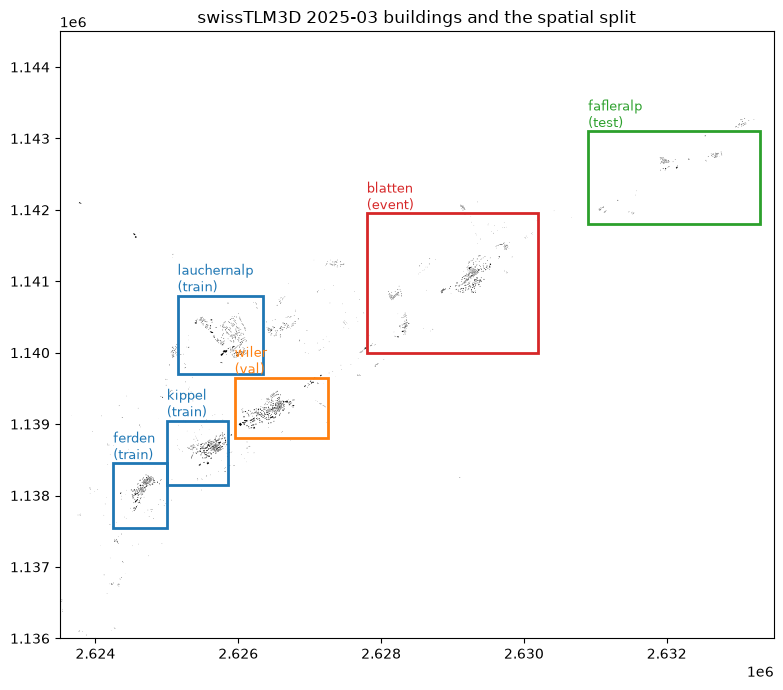

In [4]:
labels = tlm[tlm["OBJEKTART"].isin(BUILDING_TYPES)].copy()
labels_post = tlm_post[tlm_post["OBJEKTART"].isin(BUILDING_TYPES)].copy()
print(f"Label footprints: {len(labels)} of {len(tlm)}; post-event release: {len(labels_post)}")

fig, ax = plt.subplots(figsize=(12, 7))
labels.plot(ax=ax, color="black", linewidth=0)
colours = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green", "event": "tab:red"}
for name, region in REGIONS.items():
    xmin, ymin, xmax, ymax = region["bounds"]
    ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, lw=2, ec=colours[region["split"]]))
    ax.annotate(f"{name}\n({region['split']})", (xmin, ymax + 60), color=colours[region["split"]], fontsize=9)
ax.set_title(f"swissTLM3D {TLM_LABEL_RELEASE} buildings and the spatial split")
ax.set_xlim(VALLEY_BOUNDS[0], VALLEY_BOUNDS[2])
ax.set_ylim(VALLEY_BOUNDS[1], VALLEY_BOUNDS[3])
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(FIGURES / "01_spatial_split.png", dpi=150)
plt.show()

## D. Rapid Mapping orthophotos (19 and 30 May 2025)

swisstopo's Rapid Mapping flights are in the STAC collection `ch.swisstopo.spezialbefliegungen`. The
19 May flight, nine days before the collapse, provides a *quick* orthophoto (`qdop`); the 30 May flight,
two days after, provides a final RGB mosaic. Both are read for the Blatten area onto **exactly the same
0.5 m grid** as the SWISSIMAGE 2023 image of that area, which is the first condition for a pixel-by-pixel
comparison (L10 page 2).

In [5]:
event_bounds = REGIONS["blatten"]["bounds"]
rapid_paths = {}
for label, item_id, suffix in [("2025-05-19", RAPID_PRE, "-qdop-rgb-mosaic.tif"),
                               ("2025-05-30", RAPID_POST, "-rgb-mosaic.tif")]:
    items, hrefs = search_assets("ch.swisstopo.spezialbefliegungen", event_bounds, ids=[item_id], suffix=suffix)
    hrefs = [h for h in hrefs if h.endswith(item_id + suffix)]
    print(f"{label}: {items[0].id}, acquired {items[0].datetime}, asset {Path(hrefs[0]).name}")
    rapid_paths[label] = read_mosaic(hrefs, event_bounds, PROCESSED / f"rapid_{label}_blatten.tif")

2025-05-19: ram-2025-05-19t12570000, acquired 2025-05-19 12:57:00+00:00, asset ram-2025-05-19t12570000-qdop-rgb-mosaic.tif


  saved data/processed/rapid_2025-05-19_blatten.tif: 4800 x 3900 px, 72.2% valid
2025-05-30: ram-2025-05-30t08090000, acquired 2025-05-30 08:09:00+00:00, asset ram-2025-05-30t08090000-rgb-mosaic.tif


  saved data/processed/rapid_2025-05-30_blatten.tif: 4800 x 3900 px, 95.2% valid


## E. Building masks (L04)

Rasterizing with the image as the reference grid guarantees that image and mask share CRS, transform,
resolution and extent. Values: `0` = background, `1` = building. Only pixels whose centre lies inside a
footprint become building (`all_touched=False`), which keeps roofs slightly conservative.

For Blatten we write two masks: the pre-event buildings (2025-03 release) and the post-event buildings
(2026-02 release). They are **not** used for training, only to build the evaluation reference in notebook 3.

In [6]:
def write_mask(polygons, reference_path, out_path):
    """Rasterize polygons onto the grid of `reference_path` (0 = background, 1 = building)."""
    with rasterio.open(reference_path) as ref:
        profile = ref.profile.copy()
        shape, transform = (ref.height, ref.width), ref.transform
    mask = rasterize(((g, 1) for g in polygons.geometry), out_shape=shape, transform=transform,
                     fill=0, dtype="uint8", all_touched=False)
    profile.update(count=1, dtype="uint8", nodata=None)
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(mask, 1)
    return mask


masks = {}
for name in REGIONS:
    masks[name] = write_mask(labels, swissimage_paths[name], PROCESSED / f"mask{TLM_LABEL_RELEASE}_{name}.tif")
    print(f"{name:12s} building pixels: {100 * masks[name].mean():5.2f}%")
mask_post = write_mask(labels_post, swissimage_paths["blatten"], PROCESSED / f"mask{TLM_POST_RELEASE}_blatten.tif")
print(f"blatten post-event building pixels ({TLM_POST_RELEASE}): {100 * mask_post.mean():.2f}%")

ferden       building pixels:  2.44%


kippel       building pixels:  3.12%
lauchernalp  building pixels:  1.69%


wiler        building pixels:  3.12%
fafleralp    building pixels:  0.20%


blatten      building pixels:  0.63%


blatten post-event building pixels (2026-02): 0.29%


### Quality control: overlay before tiling (L06)

"The cheapest time to find a label problem is before you generate thousands of training tiles."
We look at a zoom of every region with the footprints drawn on top.

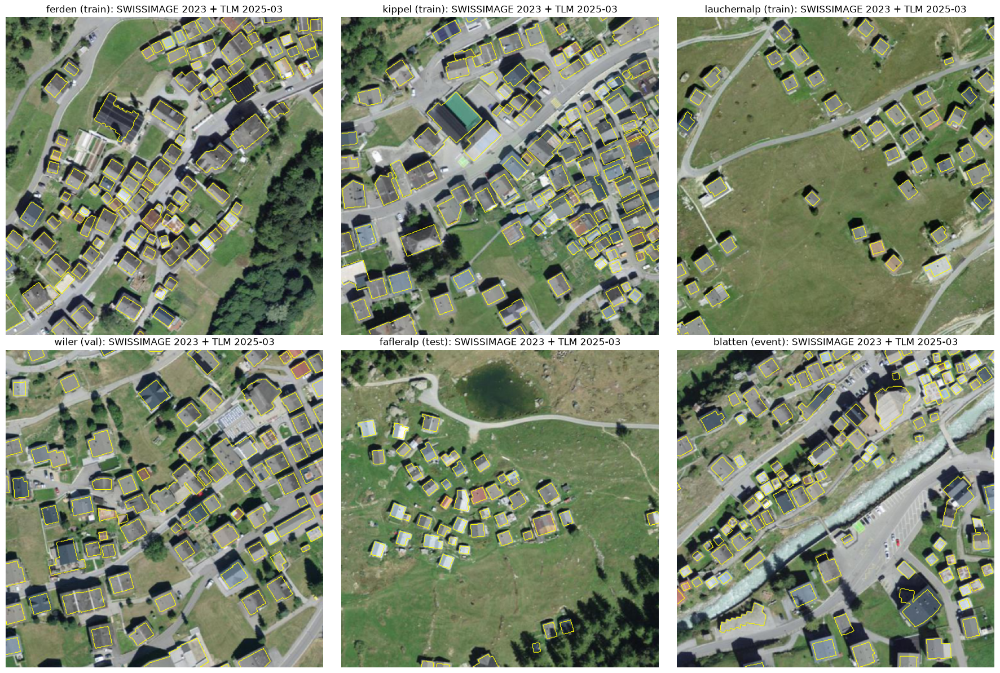

In [7]:
def read_rgb(path):
    """Read a GeoTIFF as a (rows, cols, bands) array for plotting."""
    with rasterio.open(path) as src:
        return np.moveaxis(src.read(), 0, -1)


def zoom_on_buildings(mask, size=400):
    """Return row/col slices of a `size` window centred on the densest building area."""
    rows, cols = np.nonzero(mask)
    r, c = int(np.median(rows)), int(np.median(cols))
    r0 = int(np.clip(r - size // 2, 0, mask.shape[0] - size))
    c0 = int(np.clip(c - size // 2, 0, mask.shape[1] - size))
    return slice(r0, r0 + size), slice(c0, c0 + size)


fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, name in zip(axes.flat, REGIONS):
    rgb = read_rgb(swissimage_paths[name])
    rows, cols = zoom_on_buildings(masks[name])
    ax.imshow(rgb[rows, cols])
    ax.contour(masks[name][rows, cols], levels=[0.5], colors="yellow", linewidths=0.8)
    ax.set_title(f"{name} ({REGIONS[name]['split']}): SWISSIMAGE {SWISSIMAGE_YEAR} + TLM {TLM_LABEL_RELEASE}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES / "01_label_qc.png", dpi=120)
plt.show()

The yellow outlines sit on the roofs. Two systematic effects are visible and worth knowing for the
interpretation later:

- swissTLM3D stores the **footprint** (the wall line), while the orthophoto shows the **roof**, which
  overhangs by roughly half a metre to a metre. At 0.5 m this is one or two pixels along every edge.
- Small sheds and huts are mapped individually, so very small objects (a few pixels) are part of the labels.

Both are label noise at the object edges, not wrong objects. The model will therefore never reach a
perfect edge F1; scores should be read with this in mind.

## F. Chips and spatial split (L04, L06)

Each region is cut into 256 × 256 chips. The split is decided **per region before tiling**, so no chip in
validation or test shares ground pixels with a training chip (L06, "spatial leakage"). Inside the training
villages, chips may overlap (stride 128) to give the model more positions of the same buildings; validation
and test chips do not overlap. Chips without any building are mostly forest, meadow and rock: we keep a
random 20% of them as negatives, so the model also sees enough "nothing here".

In [8]:
rng = np.random.default_rng(SEED)
records = []
for name, region in REGIONS.items():
    split = region["split"]
    if split == "event":
        continue
    stride = TRAIN_STRIDE if split == "train" else EVAL_STRIDE
    out_dir = CHIPS / split
    (out_dir / "images").mkdir(parents=True, exist_ok=True)
    (out_dir / "masks").mkdir(parents=True, exist_ok=True)
    # Slide a window over the region; the mask is already on the same grid as the image
    with rasterio.open(swissimage_paths[name]) as src:
        for row in range(0, src.height - CHIP_SIZE + 1, stride):
            for col in range(0, src.width - CHIP_SIZE + 1, stride):
                window = Window(col, row, CHIP_SIZE, CHIP_SIZE)
                image = src.read(window=window)
                mask = masks[name][row:row + CHIP_SIZE, col:col + CHIP_SIZE]
                if (image.max(axis=0) == 0).mean() > 0.01:  # skip chips with missing imagery
                    continue
                building_fraction = mask.mean()
                if building_fraction == 0 and rng.random() > KEEP_EMPTY_FRACTION:
                    continue
                chip_id = f"{name}_{row:05d}_{col:05d}"
                profile = src.profile.copy()
                profile.update(width=CHIP_SIZE, height=CHIP_SIZE, transform=src.window_transform(window), tiled=False)
                with rasterio.open(out_dir / "images" / f"{chip_id}.tif", "w", **profile) as dst:
                    dst.write(image)
                profile.update(count=1, nodata=None)
                with rasterio.open(out_dir / "masks" / f"{chip_id}.tif", "w", **profile) as dst:
                    dst.write(mask, 1)
                records.append({"chip": chip_id, "region": name, "split": split, "building_fraction": building_fraction})

chips = pd.DataFrame(records)
chips.to_csv(CHIPS / "chips.csv", index=False)
summary = chips.groupby("split").agg(
    chips=("chip", "count"),
    regions=("region", lambda r: ", ".join(sorted(set(r)))),
    with_buildings=("building_fraction", lambda f: int((f > 0).sum())),
    building_pixels_pct=("building_fraction", lambda f: round(100 * f.mean(), 2)),
)
summary.loc[["train", "val", "test"]]

,chips,regions,with_buildings,building_pixels_pct
split,,,,
train,380,"ferden, kippel, lauchernalp",337,3.91
val,40,wiler,33,5.25
test,56,fafleralp,23,0.69


The building share is only a few percent of all pixels in every split: the class imbalance from
L10 page 4 is already present in the single-date labels, and it will be even stronger for *change*.

A random sample of training chips, to check that image and mask still match after tiling:

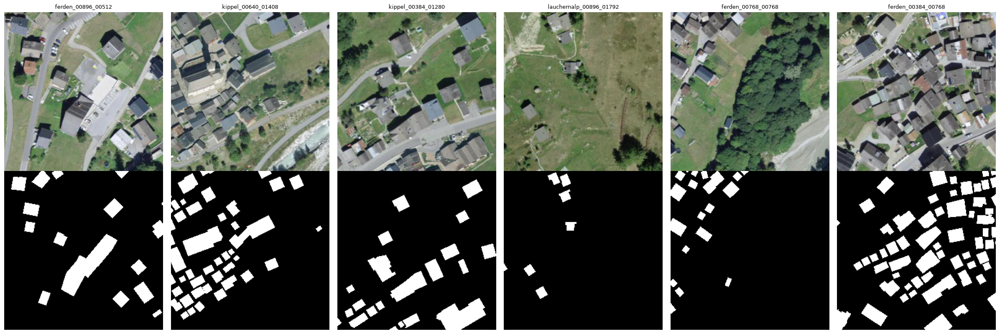

In [9]:
sample = chips[(chips.split == "train") & (chips.building_fraction > 0.02)].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for i, chip_id in enumerate(sample.chip):
    with rasterio.open(CHIPS / "train" / "images" / f"{chip_id}.tif") as src:
        axes[0, i].imshow(np.moveaxis(src.read(), 0, -1))
    with rasterio.open(CHIPS / "train" / "masks" / f"{chip_id}.tif") as src:
        axes[1, i].imshow(src.read(1), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(chip_id, fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## G. Are the two Blatten dates comparable? (L10 page 2)

Before any change detection we go through the comparability checklist for the image pair the model will
be applied to.

SWISSIMAGE 2023        valid coverage of the Blatten area: 100.0%
Rapid 2025-05-19       valid coverage of the Blatten area:  72.2%
Rapid 2025-05-30       valid coverage of the Blatten area:  95.2%
Valid on both Rapid Mapping dates:      72.2%


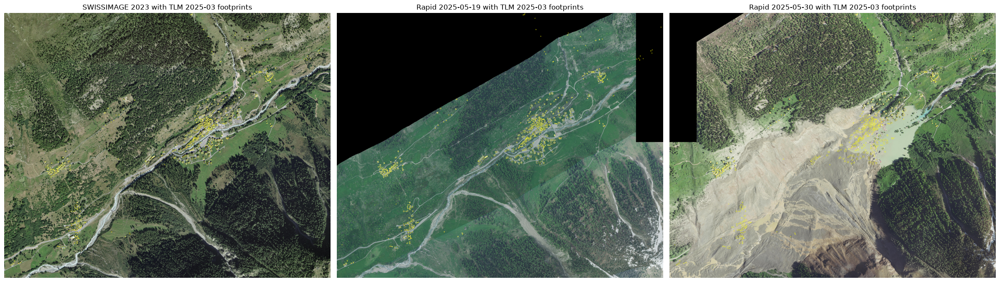

In [10]:
dates = {"SWISSIMAGE 2023": swissimage_paths["blatten"], **{f"Rapid {k}": v for k, v in rapid_paths.items()}}
event_rgb = {label: read_rgb(path) for label, path in dates.items()}
valid = {label: rgb.max(axis=2) > 0 for label, rgb in event_rgb.items()}
for label in event_rgb:
    print(f"{label:22s} valid coverage of the Blatten area: {100 * valid[label].mean():5.1f}%")
both_valid = valid["Rapid 2025-05-19"] & valid["Rapid 2025-05-30"]
print(f"Valid on both Rapid Mapping dates:     {100 * both_valid.mean():5.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (label, rgb) in zip(axes, event_rgb.items()):
    ax.imshow(rgb)
    ax.contour(masks["blatten"], levels=[0.5], colors="yellow", linewidths=0.3)
    ax.set_title(f"{label} with TLM {TLM_LABEL_RELEASE} footprints")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES / "01_blatten_dates.png", dpi=120)
plt.show()

**Co-registration.** We estimate the shift between the dates with phase correlation in an area that did
not change: the hamlet of Weissenried, west of the debris. The result is in pixels of 0.5 m. Shifts below
one pixel are harmless for a model that uses spatial context; larger shifts would create "change" along
every roof edge (page 2 figure).

In [11]:
def grey(rgb):
    """Mean of the three bands, as input for phase correlation."""
    return rgb.astype("float32").mean(axis=2)


# Weissenried: a stable window in the western part of the Blatten area (row/col on the 0.5 m grid)
transform, _, _ = region_grid(event_bounds)
col0, row0 = ~transform * (2628150, 1141050)
stable = (slice(int(row0), int(row0) + 400), slice(int(col0), int(col0) + 400))

reference = grey(event_rgb["SWISSIMAGE 2023"][stable])
rows = []
for label in ["Rapid 2025-05-19", "Rapid 2025-05-30"]:
    shift, error, _ = phase_cross_correlation(reference, grey(event_rgb[label][stable]), upsample_factor=10)
    rows.append({"image": label, "shift rows (px)": shift[0], "shift cols (px)": shift[1],
                 "shift (m)": round(float(np.hypot(*shift)) * RES, 2)})
shift, _, _ = phase_cross_correlation(grey(event_rgb["Rapid 2025-05-19"][stable]),
                                      grey(event_rgb["Rapid 2025-05-30"][stable]), upsample_factor=10)
rows.append({"image": "19 May vs 30 May", "shift rows (px)": shift[0], "shift cols (px)": shift[1],
             "shift (m)": round(float(np.hypot(*shift)) * RES, 2)})
registration = pd.DataFrame(rows).set_index("image")
registration.to_csv(PROCESSED / "coregistration_check.csv")
registration

,shift rows (px),shift cols (px),shift (m)
image,,,
Rapid 2025-05-19,1.5,0.5,0.79
Rapid 2025-05-30,-0.2,0.1,0.11
19 May vs 30 May,0.0,-0.2,0.10


**Checklist for the Blatten pair**

| Check (L10 page 2) | Finding |
|---|---|
| Change type | Abrupt (avalanche of 28 May). A bitemporal pair 11 days apart, both in late spring, is the right design. |
| Season / phenology | Both flights in late May: similar vegetation and snow on the high slopes. SWISSIMAGE 2023 is a summer image: the model is trained on a different season than it is applied to. |
| Illumination | Different times of day (12:57 and 08:09 UTC) → different shadow directions and lengths; the 19 May image is a *quick* orthophoto with stronger colour differences. |
| Co-registration | 19 May vs 30 May: about 0.1 m, far below one pixel. SWISSIMAGE 2023 vs 19 May: about 0.8 m (the quick orthophoto is less precisely fitted). |
| Resolution | All three sources are 0.1 m, resampled identically to 0.5 m; a chalet is ~20 × 24 pixels. |
| Coverage | The 19 May flight misses the north-west and north-east corners: 72% of the area is valid on both dates. Pixels without data on either date are excluded from every evaluation. |

The data are ready. Next: `02_train_change_detector.ipynb`.